# 03. 모델링

가이드 7~13단계: 가설 수립, 4가지 학습 전략 비교, 튜닝, 오류 분석, 개선 실험, 최종 평가

## 0. 공통 설정

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # notebooks/ 에서 src/ 를 import 하기 위함

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import ROOT, DATA_DIR, FIG_DIR, RESULT_DIR, CLASS_NAMES, set_seed, setup_korean_font, save_fig

SEED = 42
set_seed(SEED)
setup_korean_font()
print("프로젝트 루트:", ROOT)

프로젝트 루트: /Users/adj/Team_Project


In [2]:
import torch
from src.utils import get_device

device = get_device()
print("사용 디바이스:", device)
print("PyTorch 버전:", torch.__version__)

사용 디바이스: mps
PyTorch 버전: 2.15.0


## 7. 가설 수립

In [4]:
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet18_Weights

NUM_CLASSES = 5

def build_model(strategy):
    """전략에 맞게 ResNet18을 만들고, 학습할 층만 requires_grad=True로 남긴다."""
    weights = None if strategy == "scratch" else ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)   # 1000개 → 5개 출력으로 교체

    if strategy == "feature_extraction":          # 백본 고정, fc만 학습
        trainable = ("fc.",)
    elif strategy == "partial_ft":                # 뒤쪽 layer4 + fc만 학습
        trainable = ("layer4.", "fc.")
    else:                                         # scratch, full_ft: 전체 학습
        trainable = None

    if trainable:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith(trainable)
    return model

STRATEGIES = ["scratch", "feature_extraction", "partial_ft", "full_ft"]
rows = []
for s in STRATEGIES:
    m = build_model(s)
    total = sum(p.numel() for p in m.parameters())
    train_p = sum(p.numel() for p in m.parameters() if p.requires_grad)
    rows.append({"전략": s, "초기 가중치": "무작위" if s == "scratch" else "ImageNet",
                 "전체 파라미터": total, "학습 파라미터": train_p,
                 "학습 비율(%)": round(train_p / total * 100, 2)})
param_df = pd.DataFrame(rows)
param_df

,전략,초기 가중치,전체 파라미터,학습 파라미터,학습 비율(%)
0,scratch,무작위,11179077,11179077,100.00
1,feature_extraction,ImageNet,11179077,2565,0.02
2,partial_ft,ImageNet,11179077,8396293,75.11
3,full_ft,ImageNet,11179077,11179077,100.00


### 현재 상황 (6단계)
- ImageNet과 대상(의류)은 유사하나, 분류 기준(소재 vs 형태)과 촬영 방식은 다름
- 데이터 양: Scratch에는 적고(이미지 1장당 파라미터 약 1,300개), 전이학습에는 중간

### 주 가설
현재 데이터는 ImageNet과 저수준 시각 특징(선·질감·원단)은 유사하지만 분류 기준이 되는 고수준 특징은 다르고,
학습 데이터는 백본 전체를 새로 학습하기엔 적으므로, 사전학습된 앞쪽 층은 고정하고 뒤쪽 layer4와 분류기만 학습하는
**Partial Fine-tuning**이 분류 성능과 학습 효율 측면에서 가장 유리할 것으로 예상한다.

### 전략별 예상
| 전략 | 학습 파라미터 | 예상 성능 | 예상 근거 |
|---|---|---|---|
| Scratch | 1,118만 (100%) | 가장 낮음, 과적합 가장 큼 | 보는 법부터 8,523장으로 학습 |
| Feature Extraction | 2,565 (0.02%) | 중간, 가장 빠름 | ImageNet 특징이 소재 기준으로 묶여 있어 스커트·데님 의류 구분에 한계 |
| Partial FT (layer4+fc) | 840만 (75%) | 가장 높음 | 저수준 특징 유지 + 고수준 분류 기준만 조정 |
| Full FT | 1,118만 (100%) | Partial과 비슷하거나 약간 낮음 | 조정 범위는 가장 넓지만 데이터 대비 과적합 위험 |

### 함께 확인할 세부 예측
- Feature Extraction은 스커트 Recall이 가장 낮고, 데님 재킷·스커트가 바지로 오분류될 것
- 모든 전략에서 조끼↔민소매 상의, 와이드 바지↔맥시 스커트에서 오분류가 몰릴 것 (3단계 비율 분석)
- Partial FT는 학습 파라미터가 75%지만, 계산이 무거운 앞쪽 층 역전파를 생략해 Epoch당 시간은 Full FT보다 짧을 것

## 8. 학습 전략 비교 (Scratch / Feature Extraction / Partial FT / Full FT)

In [8]:
%load_ext autoreload
%autoreload 2

import time
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from src.data import get_loaders

loaders = get_loaders(batch_size=32)
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 8523, 'val': 1722, 'test': 2597}


In [9]:
def set_train_mode(model):
    """학습 모드로 바꾸되, 고정한 층의 BatchNorm은 평가 모드로 유지한다."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
            m.eval()   # 고정된 층의 평균·분산 통계가 우리 데이터로 바뀌지 않게


def run_epoch(model, loader, criterion, optimizer=None):
    """optimizer가 있으면 학습 1 epoch, 없으면 평가만. 손실·정확도·Macro F1을 돌려준다."""
    is_train = optimizer is not None
    if is_train:
        set_train_mode(model)
    else:
        model.eval()

    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if is_train:
                optimizer.zero_grad()
                loss.backward()        # 틀린 정도를 거꾸로 전달
                optimizer.step()       # 가중치 수정
            total_loss += loss.item() * x.size(0)
            all_preds.append(out.argmax(dim=1).cpu())
            all_labels.append(y.cpu())

    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    return {"loss": total_loss / len(loader.dataset),
            "acc": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}


# 전략별 시작 학습률 (9단계 튜닝 전 출발점)
LR = {"scratch": 1e-3, "feature_extraction": 1e-3, "partial_ft": 1e-4, "full_ft": 1e-4}

def make_optimizer(model, strategy):
    params = [p for p in model.parameters() if p.requires_grad]   # 학습하는 숫자만 넘김
    return torch.optim.Adam(params, lr=LR[strategy])

In [10]:
criterion = nn.CrossEntropyLoss()
timing_rows = []

for s in STRATEGIES:
    set_seed(SEED)
    model = build_model(s).to(device)
    optimizer = make_optimizer(model, s)

    t0 = time.time()
    tr = run_epoch(model, loaders["train"], criterion, optimizer)
    t1 = time.time()
    va = run_epoch(model, loaders["val"], criterion)
    t2 = time.time()

    timing_rows.append({"전략": s, "학습(초)": round(t1 - t0), "검증(초)": round(t2 - t1),
                        "1 epoch 합계(초)": round(t2 - t0),
                        "train_acc": round(tr["acc"], 3), "val_acc": round(va["acc"], 3),
                        "val_macro_f1": round(va["macro_f1"], 3)})
    print(f"{s}: {t2 - t0:.0f}초 | val Macro F1 {va['macro_f1']:.3f}")

timing_df = pd.DataFrame(timing_rows)
timing_df.to_csv(RESULT_DIR / "epoch_time_check.csv", index=False)
timing_df

scratch: 157초 | val Macro F1 0.552
feature_extraction: 59초 | val Macro F1 0.841
partial_ft: 77초 | val Macro F1 0.921
full_ft: 149초 | val Macro F1 0.914


,전략,학습(초),검증(초),1 epoch 합계(초),train_acc,val_acc,val_macro_f1
0,scratch,146,10,157,0.636,0.557,0.552
1,feature_extraction,49,10,59,0.786,0.840,0.841
2,partial_ft,67,10,77,0.878,0.922,0.921
3,full_ft,139,10,149,0.875,0.914,0.914


In [11]:
import json

MAX_EPOCHS = 30
PATIENCE = 5
MODEL_DIR = RESULT_DIR / "models"          # .pt 파일은 .gitignore로 업로드 제외
MODEL_DIR.mkdir(exist_ok=True)

def train_strategy(strategy, max_epochs=MAX_EPOCHS, patience=PATIENCE, tag="base"):
    set_seed(SEED)
    model = build_model(strategy).to(device)
    optimizer = make_optimizer(model, strategy)
    history, best_f1, best_epoch, wait = [], -1.0, 0, 0
    t_start = time.time()

    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        tr = run_epoch(model, loaders["train"], criterion, optimizer)
        va = run_epoch(model, loaders["val"], criterion)
        sec = time.time() - t0

        history.append({"epoch": epoch,
                        "train_loss": tr["loss"], "train_acc": tr["acc"], "train_macro_f1": tr["macro_f1"],
                        "val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": va["macro_f1"],
                        "sec": sec})
        # 매 epoch 기록 저장: 밤사이 중간에 멈춰도 그때까지 결과가 남음
        pd.DataFrame(history).to_csv(RESULT_DIR / f"history_{tag}_{strategy}.csv", index=False)
        print(f"[{strategy}] {epoch:02d} | train loss {tr['loss']:.3f} acc {tr['acc']:.3f} "
              f"| val loss {va['loss']:.3f} F1 {va['macro_f1']:.3f} | {sec:.0f}s")

        if va["macro_f1"] > best_f1:                 # 최고 기록이면 모델 저장
            best_f1, best_epoch, wait = va["macro_f1"], epoch, 0
            torch.save(model.state_dict(), MODEL_DIR / f"{tag}_{strategy}.pt")
        else:
            wait += 1
            if wait >= patience:
                print(f"  → Early stopping (최고 epoch {best_epoch}, Val Macro F1 {best_f1:.3f})")
                break

    summary = {"tag": tag, "strategy": strategy, "best_epoch": best_epoch,
               "best_val_macro_f1": round(best_f1, 4), "epochs_run": len(history),
               "total_min": round((time.time() - t_start) / 60, 1),
               "lr": LR[strategy], "batch_size": 32, "max_epochs": max_epochs,
               "patience": patience, "device": str(device)}
    with open(RESULT_DIR / f"summary_{tag}_{strategy}.json", "w") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    del model
    if device.type == "mps":
        torch.mps.empty_cache()                     # 다음 전략을 위해 GPU 메모리 정리
    return summary

In [12]:
smoke = train_strategy("feature_extraction", max_epochs=2, tag="smoke")
print(smoke)
print(sorted(p.name for p in RESULT_DIR.iterdir()))

[feature_extraction] 01 | train loss 0.671 acc 0.776 | val loss 0.462 F1 0.842 | 66s
[feature_extraction] 02 | train loss 0.428 acc 0.846 | val loss 0.398 F1 0.862 | 74s
{'tag': 'smoke', 'strategy': 'feature_extraction', 'best_epoch': 2, 'best_val_macro_f1': 0.862, 'epochs_run': 2, 'total_min': 2.3, 'lr': 0.001, 'batch_size': 32, 'max_epochs': 2, 'patience': 5, 'device': 'mps'}
['.gitkeep', 'epoch_time_check.csv', 'history_smoke_feature_extraction.csv', 'models', 'summary_smoke_feature_extraction.json']


In [13]:
all_summaries = []
for s in ["feature_extraction", "partial_ft", "full_ft"]:
    try:
        all_summaries.append(train_strategy(s))
    except Exception as e:
        print(f"!! {s} 실패: {e}")
pd.DataFrame(all_summaries)

[feature_extraction] 01 | train loss 0.668 acc 0.774 | val loss 0.482 F1 0.834 | 64s
[feature_extraction] 02 | train loss 0.432 acc 0.847 | val loss 0.421 F1 0.852 | 62s
[feature_extraction] 03 | train loss 0.383 acc 0.863 | val loss 0.397 F1 0.860 | 58s
[feature_extraction] 04 | train loss 0.357 acc 0.872 | val loss 0.381 F1 0.866 | 65s
[feature_extraction] 05 | train loss 0.339 acc 0.878 | val loss 0.375 F1 0.868 | 62s
[feature_extraction] 06 | train loss 0.327 acc 0.882 | val loss 0.377 F1 0.870 | 59s
[feature_extraction] 07 | train loss 0.313 acc 0.888 | val loss 0.367 F1 0.863 | 58s
[feature_extraction] 08 | train loss 0.307 acc 0.888 | val loss 0.363 F1 0.873 | 59s
[feature_extraction] 09 | train loss 0.303 acc 0.889 | val loss 0.359 F1 0.873 | 69s
[feature_extraction] 10 | train loss 0.295 acc 0.891 | val loss 0.361 F1 0.870 | 60s
[feature_extraction] 11 | train loss 0.284 acc 0.897 | val loss 0.351 F1 0.873 | 60s
[feature_extraction] 12 | train loss 0.280 acc 0.898 | val loss 0

,tag,strategy,best_epoch,best_val_macro_f1,epochs_run,total_min,lr,batch_size,max_epochs,patience,device
0,base,feature_extraction,12,0.8794,17,18.5,0.0010,32,30,5,mps
1,base,partial_ft,4,0.9343,9,15.5,0.0001,32,30,5,mps
2,base,full_ft,1,0.9317,6,20.9,0.0001,32,30,5,mps


저장됨: figures/02_padding_vs_stretch.png


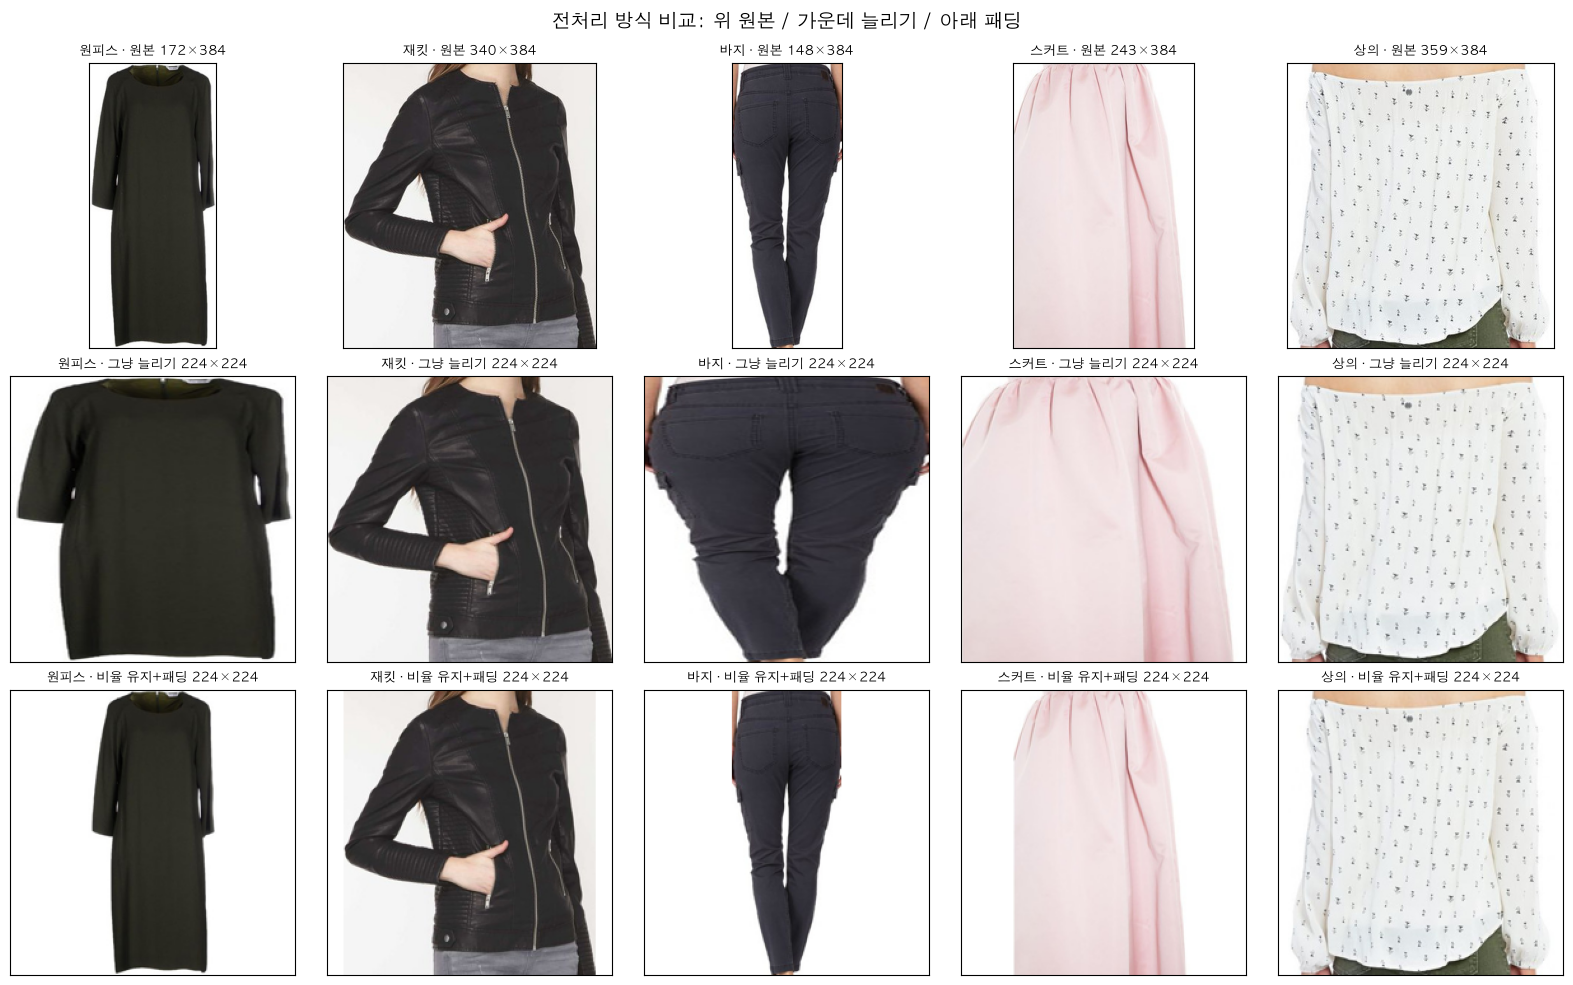

In [ ]:
pad = PadToSquare()
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for i, cat in enumerate(order):
    row = train_df[train_df["category"] == cat].sample(1, random_state=SEED).iloc[0]
    img = Image.open(DATA_DIR / row["image_path"]).convert("RGB")
    views = [(img, f"원본 {img.width}×{img.height}"),
             (img.resize((224, 224)), "그냥 늘리기 224×224"),
             (pad(img), "비율 유지+패딩 224×224")]
    for r, (v, title) in enumerate(views):
        axes[r, i].imshow(v)
        axes[r, i].set_title(f"{ko[cat]} · {title}", fontsize=9)
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])   # 테두리는 남겨서 패딩 영역이 보이게
plt.suptitle("전처리 방식 비교: 위 원본 / 가운데 늘리기 / 아래 패딩", fontsize=14)
plt.tight_layout()
save_fig("02_padding_vs_stretch")
plt.show()

저장됨: figures/02_padding_vs_stretch.png


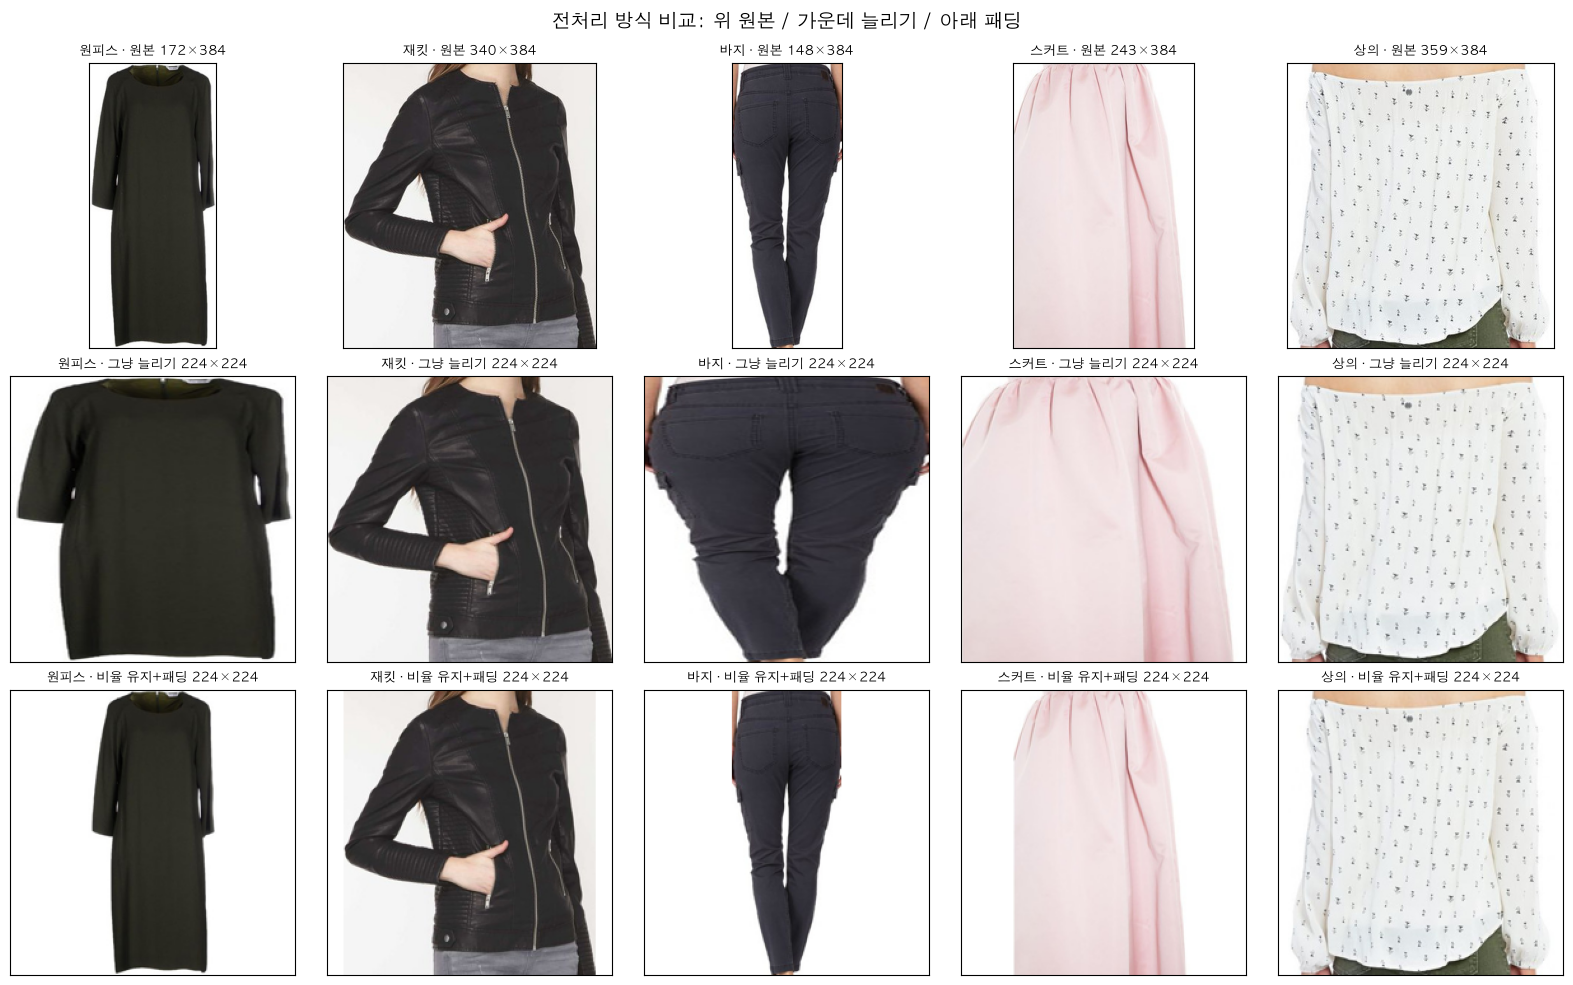

In [ ]:
pad = PadToSquare()
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for i, cat in enumerate(order):
    row = train_df[train_df["category"] == cat].sample(1, random_state=SEED).iloc[0]
    img = Image.open(DATA_DIR / row["image_path"]).convert("RGB")
    views = [(img, f"원본 {img.width}×{img.height}"),
             (img.resize((224, 224)), "그냥 늘리기 224×224"),
             (pad(img), "비율 유지+패딩 224×224")]
    for r, (v, title) in enumerate(views):
        axes[r, i].imshow(v)
        axes[r, i].set_title(f"{ko[cat]} · {title}", fontsize=9)
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])   # 테두리는 남겨서 패딩 영역이 보이게
plt.suptitle("전처리 방식 비교: 위 원본 / 가운데 늘리기 / 아래 패딩", fontsize=14)
plt.tight_layout()
save_fig("02_padding_vs_stretch")
plt.show()

/var/folders/8c/43lbrx6n2nbbz1mp9v0wbvjw0000gp/T/ipykernel_11467/218293581.py:19: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  plt.tight_layout()
/Users/adj/Team_Project/src/utils.py:76: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  plt.savefig(path, dpi=dpi, bbox_inches="tight")


저장됨: figures/08_learning_curves.png


/Users/adj/Team_Project/.venv/lib/python3.15/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) AppleGothic.
  fig.canvas.print_figure(bytes_io, **kw)


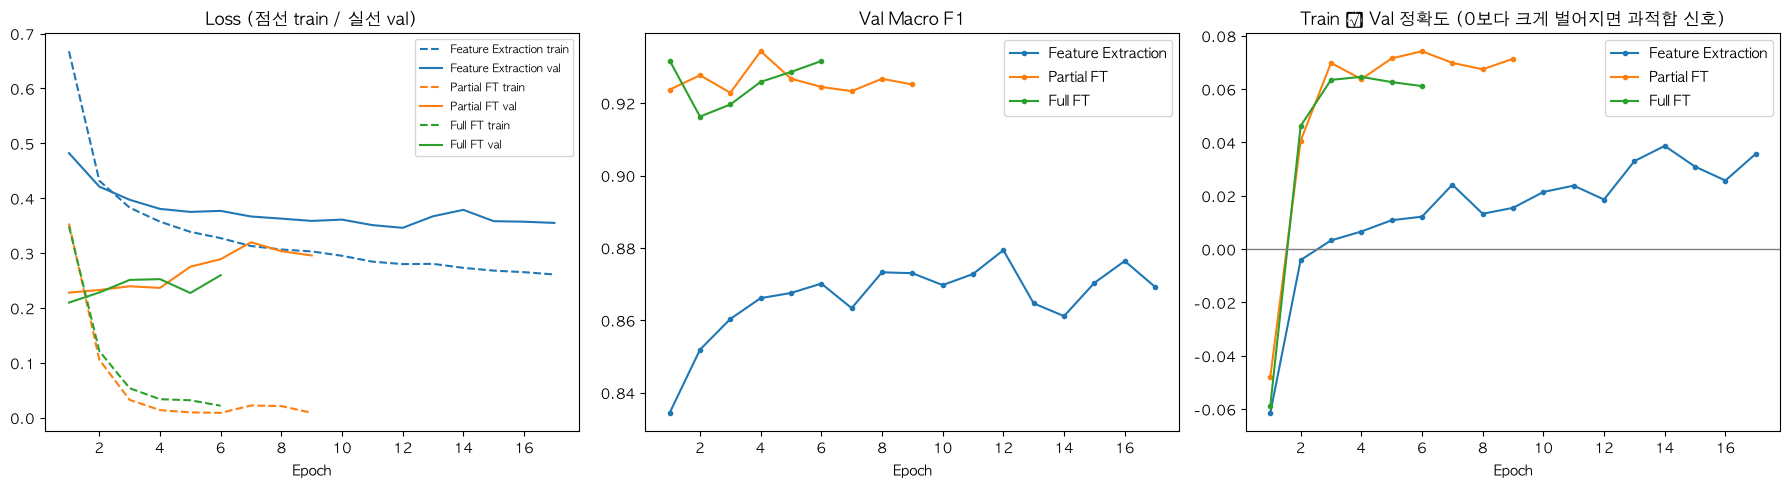

In [14]:
label = {"scratch": "Scratch", "feature_extraction": "Feature Extraction",
         "partial_ft": "Partial FT", "full_ft": "Full FT"}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for s in STRATEGIES:
    path = RESULT_DIR / f"history_base_{s}.csv"
    if not path.exists():
        continue                                   # 아직 안 돌린 전략은 건너뜀
    h = pd.read_csv(path)
    line, = axes[0].plot(h["epoch"], h["train_loss"], "--", label=f"{label[s]} train")
    axes[0].plot(h["epoch"], h["val_loss"], "-", color=line.get_color(), label=f"{label[s]} val")
    axes[1].plot(h["epoch"], h["val_macro_f1"], "-o", ms=3, label=label[s])
    axes[2].plot(h["epoch"], h["train_acc"] - h["val_acc"], "-o", ms=3, label=label[s])

axes[0].set_title("Loss (점선 train / 실선 val)"); axes[0].set_xlabel("Epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Val Macro F1"); axes[1].set_xlabel("Epoch"); axes[1].legend()
axes[2].axhline(0, color="gray", lw=1)
axes[2].set_title("Train − Val 정확도 (0보다 크게 벌어지면 과적합 신호)"); axes[2].set_xlabel("Epoch"); axes[2].legend()
plt.tight_layout()
save_fig("08_learning_curves")
plt.show()

### scratch 제외하고 먼저 돌려봄!

In [15]:
scratch_summary = train_strategy("scratch")
scratch_summary

[scratch] 01 | train loss 1.025 acc 0.592 | val loss 1.147 F1 0.532 | 151s
[scratch] 02 | train loss 0.659 acc 0.757 | val loss 0.599 F1 0.787 | 149s
[scratch] 03 | train loss 0.541 acc 0.802 | val loss 0.558 F1 0.784 | 140s
[scratch] 04 | train loss 0.501 acc 0.815 | val loss 0.616 F1 0.772 | 141s
[scratch] 05 | train loss 0.459 acc 0.830 | val loss 0.582 F1 0.789 | 139s
[scratch] 06 | train loss 0.416 acc 0.849 | val loss 0.541 F1 0.797 | 138s
[scratch] 07 | train loss 0.381 acc 0.862 | val loss 0.485 F1 0.837 | 139s
[scratch] 08 | train loss 0.371 acc 0.865 | val loss 0.555 F1 0.807 | 139s
[scratch] 09 | train loss 0.335 acc 0.877 | val loss 0.450 F1 0.841 | 170s
[scratch] 10 | train loss 0.305 acc 0.889 | val loss 0.429 F1 0.864 | 147s
[scratch] 11 | train loss 0.265 acc 0.904 | val loss 0.509 F1 0.822 | 165s
[scratch] 12 | train loss 0.264 acc 0.901 | val loss 0.419 F1 0.863 | 172s
[scratch] 13 | train loss 0.221 acc 0.918 | val loss 0.431 F1 0.857 | 140s
[scratch] 14 | train loss

{'tag': 'base',
 'strategy': 'scratch',
 'best_epoch': 10,
 'best_val_macro_f1': 0.8635,
 'epochs_run': 15,
 'total_min': 37.0,
 'lr': 0.001,
 'batch_size': 32,
 'max_epochs': 30,
 'patience': 5,
 'device': 'mps'}

저장됨: figures/02_padding_vs_stretch.png


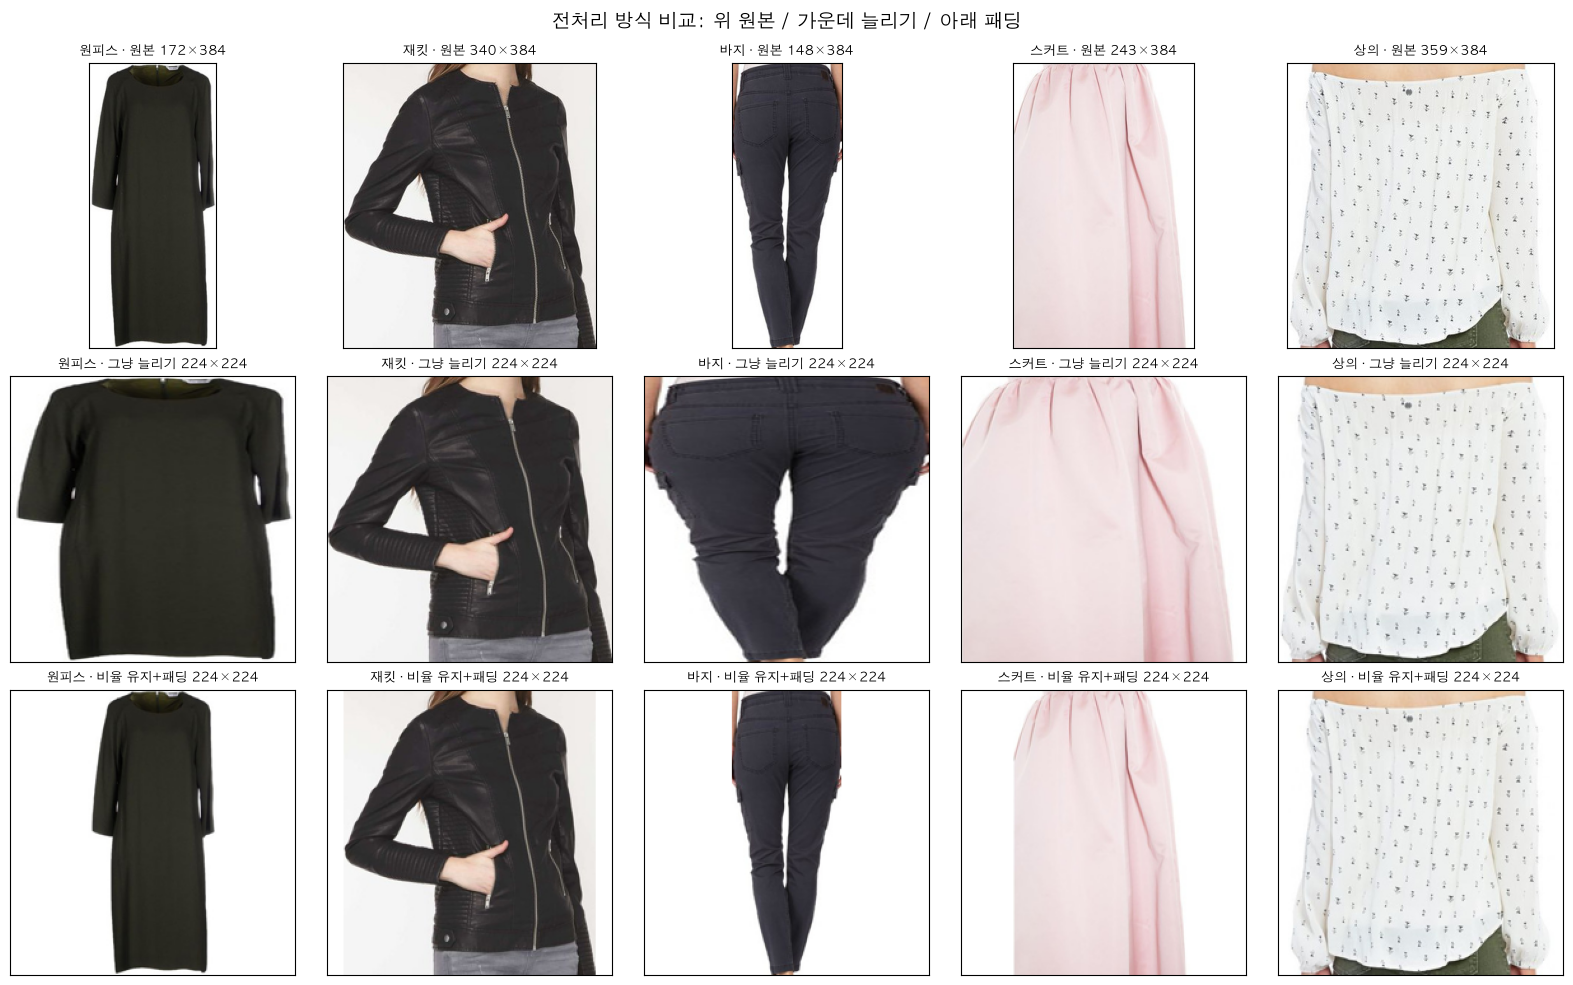

In [ ]:
pad = PadToSquare()
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for i, cat in enumerate(order):
    row = train_df[train_df["category"] == cat].sample(1, random_state=SEED).iloc[0]
    img = Image.open(DATA_DIR / row["image_path"]).convert("RGB")
    views = [(img, f"원본 {img.width}×{img.height}"),
             (img.resize((224, 224)), "그냥 늘리기 224×224"),
             (pad(img), "비율 유지+패딩 224×224")]
    for r, (v, title) in enumerate(views):
        axes[r, i].imshow(v)
        axes[r, i].set_title(f"{ko[cat]} · {title}", fontsize=9)
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])   # 테두리는 남겨서 패딩 영역이 보이게
plt.suptitle("전처리 방식 비교: 위 원본 / 가운데 늘리기 / 아래 패딩", fontsize=14)
plt.tight_layout()
save_fig("02_padding_vs_stretch")
plt.show()

In [16]:
#전체 다 합치는 코드

summaries = [json.load(open(p)) for p in sorted(RESULT_DIR.glob("summary_base_*.json"))]
summary_df = pd.DataFrame(summaries)
summary_df.to_csv(RESULT_DIR / "summary_base_all.csv", index=False)
summary_df

,tag,strategy,best_epoch,best_val_macro_f1,epochs_run,total_min,lr,batch_size,max_epochs,patience,device
0,base,feature_extraction,12,0.8794,17,18.5,0.0010,32,30,5,mps
1,base,full_ft,1,0.9317,6,20.9,0.0001,32,30,5,mps
2,base,partial_ft,4,0.9343,9,15.5,0.0001,32,30,5,mps
3,base,scratch,10,0.8635,15,37.0,0.0010,32,30,5,mps


In [17]:
h = pd.read_csv(RESULT_DIR / "history_base_full_ft.csv")
h[["epoch", "train_loss", "val_loss", "val_macro_f1"]].round(4)

,epoch,train_loss,val_loss,val_macro_f1
0,1,0.3488,0.2098,0.9317
1,2,0.1214,0.2282,0.9163
2,3,0.0538,0.2512,0.9196
3,4,0.0338,0.2526,0.9259
4,5,0.0319,0.2273,0.9286
5,6,0.0219,0.2597,0.9316


## 9. 하이퍼파라미터 튜닝

### 9-1. 튜닝 원칙
- 비교 기준은 **Val Macro F1**만 사용하고, Test는 최종 모델 확정 전까지 사용하지 않는다.
- 한 번에 **하나의 하이퍼파라미터만** 바꿔, 성능 변화의 원인을 분리한다.
- patience(5), max epoch(30), batch size(32), 이미지 크기, 모델 구조(ResNet18)는 base와 동일하게 고정한다.

### 9-2. 1단계: 학습률
base 실험에서 관찰한 문제와 가설은 다음과 같다.

| 전략 | 관찰 | 가설 | base → 실험 |
|---|---|---|---|
| Full FT | 1 epoch에 Val loss 최저, 2 epoch에 F1 0.015 하락 후 회복 | 학습률이 커서 좋은 지점을 지나침 | 1e-4 → 3e-5 |
| Partial FT | train loss 4 epoch 만에 ≈0, Val loss 상승 | 더 천천히 학습하면 더 정확한 지점에 도달 | 1e-4 → 3e-5 |
| Scratch | Val F1 톱니 흔들림, 15 epoch 붕괴 | 학습률이 커서 불안정 | 1e-3 → 3e-4 |

**예상 소요 시간 (최대 30 epoch 기준, 보수적)**: Full FT 약 105분 + Partial FT 약 52분 + Scratch 약 75분 ≈ 4시간

In [ ]:
# ===== 9-2-1. 짧은 점검: 학습/검증/저장이 정상 동작하는지 2 epoch만 실행 =====
LR_TUNING = [
    # (전략, 실험 학습률, tag)
    ("full_ft",    3e-5, "lr3e-5"),
    ("partial_ft", 3e-5, "lr3e-5"),
    ("scratch",    3e-4, "lr3e-4"),   # 시간이 부족하면 이 줄을 주석 처리
]
BASE_LR = dict(LR)                    # base 학습률 백업 (실험 후 되돌리기용)

LR["partial_ft"] = 3e-5
smoke = train_strategy("partial_ft", max_epochs=2, tag="smoke")
LR.update(BASE_LR)                    # 원래 값으로 복구
smoke

[partial_ft] 01 | train loss 0.501 acc 0.830 | val loss 0.293 F1 0.906 | 85s
[partial_ft] 02 | train loss 0.213 acc 0.930 | val loss 0.245 F1 0.918 | 88s


{'tag': 'smoke',
 'strategy': 'partial_ft',
 'best_epoch': 2,
 'best_val_macro_f1': 0.9176,
 'epochs_run': 2,
 'total_min': 2.9,
 'lr': 3e-05,
 'batch_size': 32,
 'max_epochs': 2,
 'patience': 5,
 'device': 'mps'}

In [ ]:
# ===== 9-2-2. 1단계 튜닝: 학습률 (전략별 순차 실행) =====
tune_results = []
for strategy, lr, tag in LR_TUNING:
    LR[strategy] = lr
    print(f"\n===== {strategy} | lr {lr} | tag {tag} =====")
    try:
        tune_results.append(train_strategy(strategy, tag=tag))
    except Exception as e:                       # 한 실험이 실패해도 다음 실험은 계속
        print(f"  ✗ {strategy} 실패: {e}")
    finally:
        LR.update(BASE_LR)                       # 다음 실험 전에 항상 원래 값으로 복구

pd.DataFrame(tune_results)


===== full_ft | lr 3e-05 | tag lr3e-5 =====
[full_ft] 01 | train loss 0.489 acc 0.833 | val loss 0.272 F1 0.903 | 144s
[full_ft] 02 | train loss 0.183 acc 0.939 | val loss 0.235 F1 0.923 | 147s
[full_ft] 03 | train loss 0.089 acc 0.976 | val loss 0.224 F1 0.925 | 145s
[full_ft] 04 | train loss 0.042 acc 0.993 | val loss 0.234 F1 0.924 | 145s
[full_ft] 05 | train loss 0.024 acc 0.997 | val loss 0.240 F1 0.924 | 154s
[full_ft] 06 | train loss 0.014 acc 0.999 | val loss 0.220 F1 0.936 | 145s
[full_ft] 07 | train loss 0.012 acc 0.998 | val loss 0.248 F1 0.925 | 144s
[full_ft] 08 | train loss 0.009 acc 0.999 | val loss 0.243 F1 0.934 | 144s
[full_ft] 09 | train loss 0.008 acc 0.999 | val loss 0.265 F1 0.930 | 175s
[full_ft] 10 | train loss 0.013 acc 0.997 | val loss 0.286 F1 0.918 | 164s
[full_ft] 11 | train loss 0.009 acc 0.998 | val loss 0.267 F1 0.925 | 165s
  → Early stopping (최고 epoch 6, Val Macro F1 0.936)

===== partial_ft | lr 3e-05 | tag lr3e-5 =====
[partial_ft] 01 | train loss 0

,tag,strategy,best_epoch,best_val_macro_f1,epochs_run,total_min,lr,batch_size,max_epochs,patience,device
0,lr3e-5,full_ft,6,0.9358,11,27.9,0.00003,32,30,5,mps
1,lr3e-5,partial_ft,14,0.9378,19,30.0,0.00003,32,30,5,mps
2,lr3e-4,scratch,5,0.8510,10,30.7,0.00030,32,30,5,mps


In [ ]:
# ===== 9-2-3. base vs 학습률 튜닝 비교 =====
import json

rows = [json.load(open(p)) for p in sorted(RESULT_DIR.glob("summary_*.json"))
        if "smoke" not in p.name]
summary_all = pd.DataFrame(rows)

compare = (summary_all[summary_all["tag"].isin(["base", "lr3e-5", "lr3e-4"])]
           [["strategy", "tag", "lr", "best_epoch", "best_val_macro_f1", "epochs_run", "total_min"]]
           .sort_values(["strategy", "tag"]).reset_index(drop=True))
compare.to_csv(RESULT_DIR / "compare_lr_tuning.csv", index=False)
compare

,strategy,tag,lr,best_epoch,best_val_macro_f1,epochs_run,total_min
0,feature_extraction,base,0.00100,12,0.8794,17,18.5
1,full_ft,base,0.00010,1,0.9317,6,20.9
2,full_ft,lr3e-5,0.00003,6,0.9358,11,27.9
3,partial_ft,base,0.00010,4,0.9343,9,15.5
4,partial_ft,lr3e-5,0.00003,14,0.9378,19,30.0
5,scratch,base,0.00100,10,0.8635,15,37.0
6,scratch,lr3e-4,0.00030,5,0.8510,10,30.7


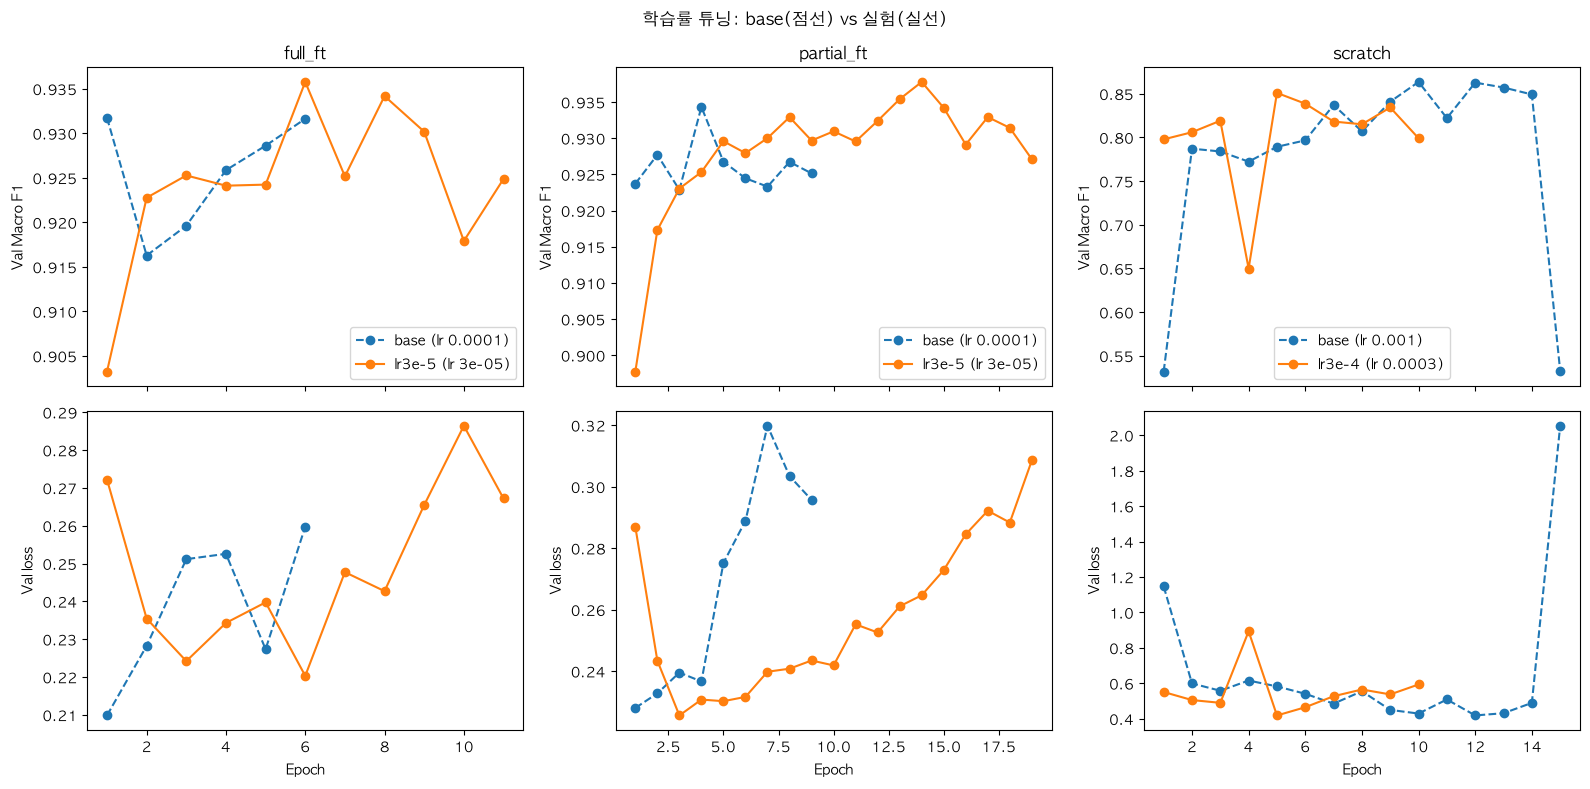

In [ ]:
# ===== 9-2-4. 전략별 base vs 튜닝 Val Macro F1 / Val loss 곡선 =====
import matplotlib.pyplot as plt

FIG_DIR = RESULT_DIR.parent / "figures"          # 이미 FIG_DIR이 있으면 이 줄은 지워도 됨
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex="col")
for col, (strategy, lr, tag) in enumerate(LR_TUNING):
    for t, style in [("base", "--"), (tag, "-")]:
        path = RESULT_DIR / f"history_{t}_{strategy}.csv"
        if not path.exists():
            continue
        h = pd.read_csv(path)
        label = f"{t} (lr {BASE_LR[strategy] if t == 'base' else lr})"
        axes[0, col].plot(h["epoch"], h["val_macro_f1"], style, marker="o", label=label)
        axes[1, col].plot(h["epoch"], h["val_loss"], style, marker="o", label=label)
    axes[0, col].set_title(strategy)
    axes[0, col].set_ylabel("Val Macro F1")
    axes[1, col].set_ylabel("Val loss")
    axes[1, col].set_xlabel("Epoch")
    axes[0, col].legend()

plt.suptitle("학습률 튜닝: base(점선) vs 실험(실선)")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_lr_tuning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 9-3. 1단계 결과 해석

| 전략 | base → 실험 lr | Val Macro F1 | best epoch | 가설 |
|---|---|---|---|---|
| Full FT | 1e-4 → 3e-5 | 0.9317 → 0.9358 | 1 → 6 | ✅ 확인 |
| Partial FT | 1e-4 → 3e-5 | 0.9343 → **0.9378** | 4 → 14 | ✅ 확인 |
| Scratch | 1e-3 → 3e-4 | 0.8635 → 0.8510 | 10 → 5 | ❌ 일부 기각 |

- **Full FT**: base에서 보인 2 epoch 하락(0.932 → 0.916)이 사라지고, F1 최고와 Val loss 최저가 같은 6 epoch에서 일치했다. 학습률이 커서 좋은 지점을 지나쳤다는 가설이 확인되었다.
- **Partial FT**: Val loss 상승이 base(3 epoch 만에 0.237 → 0.320)보다 훨씬 완만해졌다(16 epoch에 걸쳐 0.226 → 0.309). 과적합 시점이 늦춰지고 F1이 꾸준히 상승했다.
- **Scratch**: 초기 학습은 안정되었으나(1 epoch F1 0.53 → 0.80) 4 epoch에 붕괴(F1 0.65)가 다시 발생했다. 불안정의 원인이 학습률만이 아님을 확인하고, Scratch는 base를 기준선으로 유지한다.
- F1 변화폭(+0.004)은 잡음 기준(±0.01) 이내로, 학습률 조정의 주된 효과는 **성능 향상보다 학습 안정성**이다.
- Partial FT에서 Val loss는 3 epoch부터 오르지만 F1은 14 epoch까지 오른다. 틀린 예측에 대한 **과한 확신**이 남아 있으므로, 2단계에서 Label Smoothing·증강·Weight Decay를 비교한다.

**2단계 기준 설정**: Partial FT, lr 3e-5

### 9-4. 2단계: 온도 조절로 과신 진단 (학습 없음)

1단계 최적 모델(Partial FT, lr 3e-5)의 Val 예측으로 보정 상태를 확인한다.
- 온도 T로 logit을 나누면 예측 순서(F1)는 그대로이고 확신도만 바뀐다.
- Val NLL을 최소화하는 최적 T를 구하고, 구간별 확신도 vs 정답률(보정 표)과 ECE를 비교한다.

**판단 기준**
- 최적 T가 1보다 확실히 크고(약 1.2 이상) ECE가 크게 줄어듦 → 과신 확인 → 3단계 Label Smoothing 실험
- 최적 T가 1 근처(약 0.9~1.1) → 과신 아님 → 3단계를 건너뛰고 4단계 개선 실험에 시간 투자

※ 이 T는 진단용이다. 최종 모델이 정해지면 그 모델로 T를 다시 구한다. Test는 사용하지 않는다.

In [26]:
# ===== 9-4-1. 최고 모델의 Val logit 수집 =====
import json
import torch.nn.functional as F
from src.data import get_loaders, get_transform   # get_transform: 실수로 덮어쓴 함수 원래대로 복구

loaders = get_loaders(batch_size=32)               # base 설정 (증강 없음)
best_path = MODEL_DIR / "lr3e-5_partial_ft.pt"

model = build_model("partial_ft").to(device)
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

logit_list, label_list = [], []
with torch.no_grad():
    for x, y in loaders["val"]:
        logit_list.append(model(x.to(device)).cpu())
        label_list.append(y)
val_logits, val_labels = torch.cat(logit_list), torch.cat(label_list)

print("Val 사진 수:", len(val_labels))
print("T=1 Val loss:", round(F.cross_entropy(val_logits, val_labels).item(), 4))
print("T=1 Val Macro F1:", round(f1_score(val_labels.numpy(), val_logits.argmax(1).numpy(), average="macro"), 4))

Val 사진 수: 1722
T=1 Val loss: 0.2647
T=1 Val Macro F1: 0.9378


In [28]:
# ===== 9-4-2. 최적 온도 T 찾기 + 보정 표 =====
Ts = np.round(np.arange(0.5, 5.01, 0.05), 2)
nll = [F.cross_entropy(val_logits / t, val_labels).item() for t in Ts]
best_T = float(Ts[int(np.argmin(nll))])
nll_T1 = F.cross_entropy(val_logits, val_labels).item()

def calibration_table(logits, labels, T=1.0, n_bins=10):
    """확신도 구간별로 '평균 확신도'와 '실제 정답률'을 비교. ECE = 구간별 차이의 가중 평균"""
    prob = (logits / T).softmax(1)
    conf, pred = prob.max(1)
    correct = (pred == labels).float()
    edges = np.linspace(0, 1, n_bins + 1)
    rows, ece = [], 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        c, a, n = conf[m].mean().item(), correct[m].mean().item(), int(m.sum())
        rows.append({"구간": f"{lo:.1f}~{hi:.1f}", "개수": n,
                     "평균 확신도": round(c, 3), "정답률": round(a, 3), "확신-정답": round(c - a, 3)})
        ece += n / len(labels) * abs(c - a)
    return pd.DataFrame(rows), ece

tab_1, ece_1 = calibration_table(val_logits, val_labels, T=1.0)
tab_T, ece_T = calibration_table(val_logits, val_labels, T=best_T)

print(f"최적 T = {best_T}")
print(f"Val NLL : T=1 {nll_T1:.4f} → T={best_T} {min(nll):.4f}")
print(f"ECE     : T=1 {ece_1:.4f} → T={best_T} {ece_T:.4f}")
print("F1 변화 없음 확인:",
      round(f1_score(val_labels.numpy(), (val_logits / best_T).argmax(1).numpy(), average="macro"), 4))

calib_summary = {"model": "lr3e-5_partial_ft", "best_T": best_T,
                 "nll_T1": round(nll_T1, 4), "nll_bestT": round(min(nll), 4),
                 "ece_T1": round(ece_1, 4), "ece_bestT": round(ece_T, 4)}
with open(RESULT_DIR / "calibration_diagnosis.json", "w") as f:
    json.dump(calib_summary, f, ensure_ascii=False, indent=2)
tab_1

최적 T = 1.65
Val NLL : T=1 0.2647 → T=1.65 0.2229
ECE     : T=1 0.0310 → T=1.65 0.0161
F1 변화 없음 확인: 0.9378


,구간,개수,평균 확신도,정답률,확신-정답
0,0.4~0.5,8,0.468,0.750,-0.282
1,0.5~0.6,38,0.541,0.579,-0.038
2,0.6~0.7,37,0.661,0.703,-0.042
3,0.7~0.8,44,0.760,0.659,0.101
4,0.8~0.9,62,0.844,0.774,0.070
5,0.9~1.0,1533,0.994,0.968,0.026


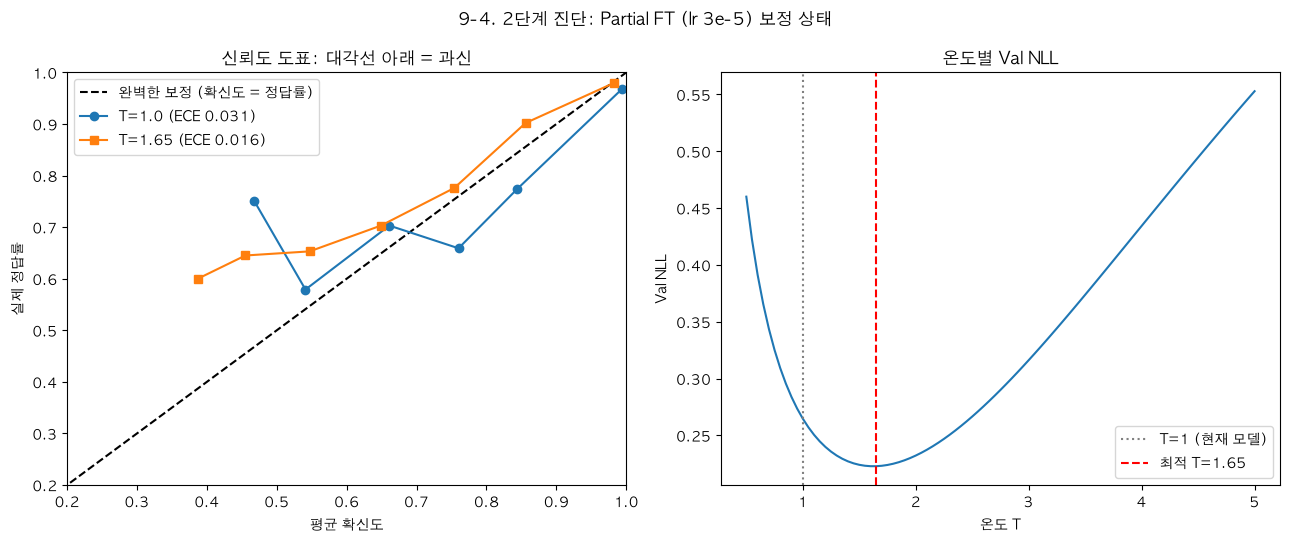

In [29]:
# ===== 9-4-3. 보정 그래프: 신뢰도 도표 + 온도별 NLL =====
FIG_DIR = RESULT_DIR.parent / "figures"
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
ax.plot([0, 1], [0, 1], "k--", label="완벽한 보정 (확신도 = 정답률)")
for tab, T, ece, style in [(tab_1, 1.0, ece_1, "o-"), (tab_T, best_T, ece_T, "s-")]:
    ax.plot(tab["평균 확신도"], tab["정답률"], style, label=f"T={T} (ECE {ece:.3f})")
ax.set_xlabel("평균 확신도"); ax.set_ylabel("실제 정답률")
ax.set_title("신뢰도 도표: 대각선 아래 = 과신")
ax.set_xlim(0.2, 1.0); ax.set_ylim(0.2, 1.0); ax.legend()

ax = axes[1]
ax.plot(Ts, nll)
ax.axvline(1.0, color="gray", ls=":", label="T=1 (현재 모델)")
ax.axvline(best_T, color="red", ls="--", label=f"최적 T={best_T}")
ax.set_xlabel("온도 T"); ax.set_ylabel("Val NLL"); ax.set_title("온도별 Val NLL")
ax.legend()

plt.suptitle("9-4. 2단계 진단: Partial FT (lr 3e-5) 보정 상태")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_calibration_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

#### 9-4 결과 해석

| 지표 | T = 1 (현재) | T = 1.65 (최적) |
|---|---|---|
| Val NLL | 0.2647 | 0.2229 (−16%) |
| ECE | 0.031 | 0.016 (−48%) |
| Val Macro F1 | 0.9378 | 0.9378 (변화 없음) |

- 최적 T = 1.65로 판단 기준(약 1.2 이상)을 충족해 **과신이 확인**되었다.
- Val 오답 약 107장 중 49장(46%)이 확신도 0.9 이상 구간(평균 확신도 0.994)에서 발생한다. 1단계에서 관찰한 "Val loss 상승 + F1 상승"은 이 고확신 오답에서 비롯된 것으로 해석된다.
- 단일 T 적용 시 0.9 이상 구간은 보정되지만 0.4~0.7 구간은 과소확신으로 바뀐다. 사후 보정만으로는 한계가 있어, 학습 단계에서 과신을 줄이는 Label Smoothing을 3단계에서 비교한다.
- 고확신 오답에는 라벨 오류가 포함될 수 있으므로, 10~11단계 오분류 분석에서 이미지와 원본 상품 정보를 함께 확인한다.

**결정**: 3단계 Label Smoothing 실험 진행 (Partial FT, lr 3e-5, label_smoothing 0.1)

## 9-5. 3단계: Label Smoothing

9-4 진단에서 과신이 확인되었으므로(최적 T = 1.65), 1단계 최적 설정에서 **label_smoothing만 0 → 0.1로** 바꿔 비교한다.

- 기준: Partial FT, lr 3e-5 (`lr3e-5`, Val Macro F1 0.9378)
- 실험: 위와 동일 + label_smoothing 0.1 (`ls0.1`)
- 학습 중 loss는 smoothing이 포함되어 바닥값이 약 0.39이므로 기준 실험과 직접 비교하지 않는다. 두 모델을 일반 NLL로 다시 평가해 비교한다.

**가설**: 학습 단계에서 과신이 줄어, 최적 T가 1에 가까워지고 고확신(0.9 이상) 오답이 줄어든다. F1은 라벨 노이즈 가능성 때문에 크게 오르지 않을 수 있다.

**후속 판단**
- ls0.1 모델의 최적 T가 1 근처 → 0.1로 확정
- 최적 T가 1보다 확실히 작음(과소확신) → 0.1이 과함 → 0.05 1회 추가
- 최적 T가 여전히 1.2 이상 → 0.2 1회 추가 검토

**예상 소요 시간**: 약 30분 (최대 30 epoch 기준 약 48분)

In [30]:
# ===== 9-5-1. 짧은 점검: label_smoothing 0.1, 1 epoch =====
LS = 0.1
criterion = nn.CrossEntropyLoss(label_smoothing=LS)
LR["partial_ft"] = 3e-5
try:
    smoke = train_strategy("partial_ft", max_epochs=1, tag="smoke_ls")
finally:
    LR.update(BASE_LR)                       # 원래 학습률로 복구
    criterion = nn.CrossEntropyLoss()        # 원래 손실 함수로 복구
smoke

[partial_ft] 01 | train loss 0.755 acc 0.833 | val loss 0.616 F1 0.905 | 97s


{'tag': 'smoke_ls',
 'strategy': 'partial_ft',
 'best_epoch': 1,
 'best_val_macro_f1': 0.9045,
 'epochs_run': 1,
 'total_min': 1.6,
 'lr': 3e-05,
 'batch_size': 32,
 'max_epochs': 1,
 'patience': 5,
 'device': 'mps'}

In [31]:
# ===== 9-5-2. 3단계 본 실험: Partial FT + lr 3e-5 + label_smoothing 0.1 =====
criterion = nn.CrossEntropyLoss(label_smoothing=LS)
LR["partial_ft"] = 3e-5
try:
    ls_result = train_strategy("partial_ft", tag="ls0.1")
finally:
    LR.update(BASE_LR)
    criterion = nn.CrossEntropyLoss()
ls_result

[partial_ft] 01 | train loss 0.755 acc 0.835 | val loss 0.615 F1 0.911 | 94s
[partial_ft] 02 | train loss 0.558 acc 0.940 | val loss 0.592 F1 0.918 | 94s
[partial_ft] 03 | train loss 0.495 acc 0.977 | val loss 0.582 F1 0.923 | 79s
[partial_ft] 04 | train loss 0.457 acc 0.993 | val loss 0.578 F1 0.925 | 75s
[partial_ft] 05 | train loss 0.433 acc 0.999 | val loss 0.578 F1 0.927 | 77s
[partial_ft] 06 | train loss 0.423 acc 1.000 | val loss 0.576 F1 0.925 | 78s
[partial_ft] 07 | train loss 0.417 acc 1.000 | val loss 0.580 F1 0.925 | 84s
[partial_ft] 08 | train loss 0.412 acc 1.000 | val loss 0.580 F1 0.922 | 85s
[partial_ft] 09 | train loss 0.409 acc 1.000 | val loss 0.580 F1 0.925 | 94s
[partial_ft] 10 | train loss 0.407 acc 1.000 | val loss 0.577 F1 0.924 | 101s
  → Early stopping (최고 epoch 5, Val Macro F1 0.927)


{'tag': 'ls0.1',
 'strategy': 'partial_ft',
 'best_epoch': 5,
 'best_val_macro_f1': 0.9265,
 'epochs_run': 10,
 'total_min': 14.4,
 'lr': 3e-05,
 'batch_size': 32,
 'max_epochs': 30,
 'patience': 5,
 'device': 'mps'}

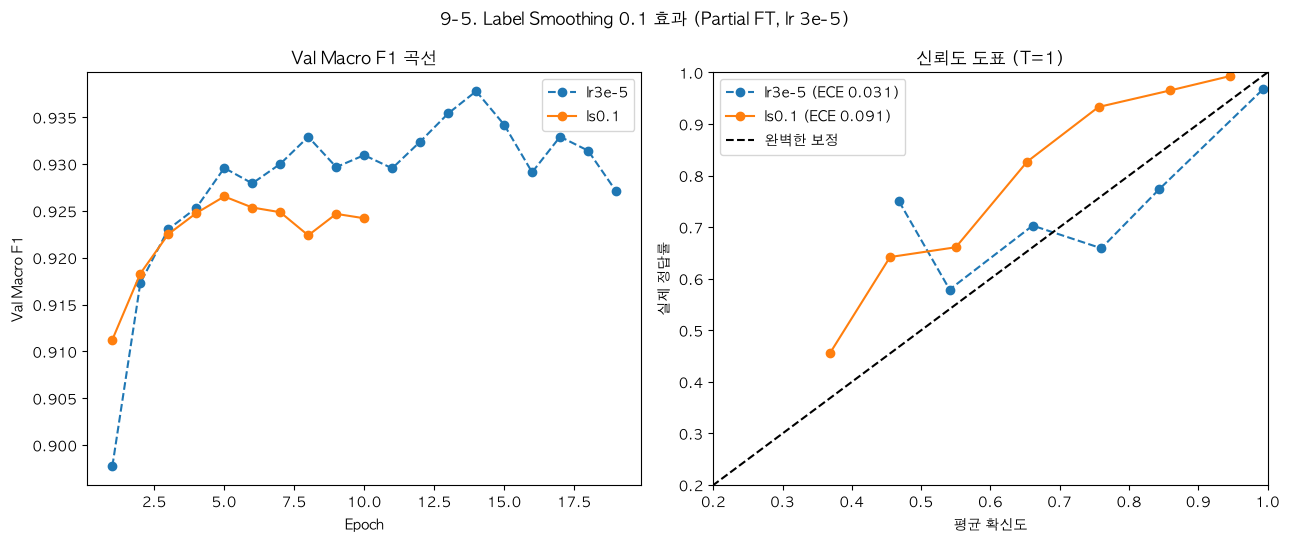

,tag,Val Macro F1,NLL (T=1),ECE (T=1),최적 T,오답 수,확신 0.9↑ 오답 수
0,lr3e-5,0.9378,0.2647,0.0310,1.65,107,49
1,ls0.1,0.9265,0.2905,0.0907,0.65,126,6


In [32]:
# ===== 9-5-3. lr3e-5 vs ls0.1: 같은 기준(일반 NLL, ECE, 최적 T)으로 비교 =====
def get_val_logits(path):
    m = build_model("partial_ft").to(device)
    m.load_state_dict(torch.load(path, map_location=device))
    m.eval()
    outs = []
    with torch.no_grad():
        for x, _ in loaders["val"]:
            outs.append(m(x.to(device)).cpu())
    del m
    return torch.cat(outs)

rows, tabs = [], {}
for tag in ["lr3e-5", "ls0.1"]:
    lg = get_val_logits(MODEL_DIR / f"{tag}_partial_ft.pt")
    nll_t = [F.cross_entropy(lg / t, val_labels).item() for t in Ts]
    bT = float(Ts[int(np.argmin(nll_t))])
    tab, ece = calibration_table(lg, val_labels, T=1.0)
    conf, pred = lg.softmax(1).max(1)
    tabs[tag] = (tab, ece)
    rows.append({"tag": tag,
                 "Val Macro F1": round(f1_score(val_labels.numpy(), pred.numpy(), average="macro"), 4),
                 "NLL (T=1)": round(F.cross_entropy(lg, val_labels).item(), 4),
                 "ECE (T=1)": round(ece, 4),
                 "최적 T": bT,
                 "오답 수": int((pred != val_labels).sum()),
                 "확신 0.9↑ 오답 수": int(((pred != val_labels) & (conf > 0.9)).sum())})

ls_compare = pd.DataFrame(rows)
ls_compare.to_csv(RESULT_DIR / "compare_label_smoothing.csv", index=False)

# 그래프: Val F1 곡선 + 신뢰도 도표(T=1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for tag, style in [("lr3e-5", "--"), ("ls0.1", "-")]:
    h = pd.read_csv(RESULT_DIR / f"history_{tag}_partial_ft.csv")
    axes[0].plot(h["epoch"], h["val_macro_f1"], style, marker="o", label=tag)
    tab, ece = tabs[tag]
    axes[1].plot(tab["평균 확신도"], tab["정답률"], style, marker="o", label=f"{tag} (ECE {ece:.3f})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Macro F1"); axes[0].set_title("Val Macro F1 곡선"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k--", label="완벽한 보정")
axes[1].set_xlim(0.2, 1.0); axes[1].set_ylim(0.2, 1.0)
axes[1].set_xlabel("평균 확신도"); axes[1].set_ylabel("실제 정답률"); axes[1].set_title("신뢰도 도표 (T=1)"); axes[1].legend()
plt.suptitle("9-5. Label Smoothing 0.1 효과 (Partial FT, lr 3e-5)")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_label_smoothing.png", dpi=150, bbox_inches="tight")
plt.show()

ls_compare

In [33]:
# ===== 9-5-4. 각자 최적 T로 보정한 뒤 비교 (공정 비교) =====
fair_rows = []
for tag in ["lr3e-5", "ls0.1"]:
    lg = get_val_logits(MODEL_DIR / f"{tag}_partial_ft.pt")
    nll_t = [F.cross_entropy(lg / t, val_labels).item() for t in Ts]
    bT = float(Ts[int(np.argmin(nll_t))])
    _, ece_bT = calibration_table(lg, val_labels, T=bT)
    fair_rows.append({"tag": tag, "최적 T": bT,
                      "NLL (최적 T)": round(min(nll_t), 4),
                      "ECE (최적 T)": round(ece_bT, 4)})
ls_fair = pd.DataFrame(fair_rows)
ls_fair.to_csv(RESULT_DIR / "compare_label_smoothing_calibrated.csv", index=False)
ls_fair

,tag,최적 T,NLL (최적 T),ECE (최적 T)
0,lr3e-5,1.65,0.2229,0.0161
1,ls0.1,0.65,0.2362,0.0104


#### 9-5 결과 해석

| 지표 | lr3e-5 (기준) | ls0.1 |
|---|---|---|
| Val Macro F1 | **0.9378** (14 epoch) | 0.9266 (5 epoch) |
| ECE (T=1) | **0.031** (과신) | 0.091 (과소확신) |
| 최적 T | 1.65 | 0.65 |
| NLL (최적 T) | **0.2229** | 0.2362 |
| ECE (최적 T) | 0.0161 | 0.0104 |

- **가설 기각**: Label Smoothing 0.1은 과신을 줄이는 데서 그치지 않고 과소확신을 만들었다(신뢰도 도표가 대각선 위, 최적 T 0.65).
- 원인: Val의 약 89%가 정답률 97% 수준의 쉬운 이미지인데, smoothing이 모든 이미지의 확신을 약 92% 근처로 제한했기 때문으로 해석된다.
- 각자 최적 T로 보정한 뒤에도 NLL은 기준 모델이 더 낮고, F1도 기준 모델이 높다. ECE 차이(0.006)는 구간 표본 수가 적어 판단 근거로 삼지 않는다.
- Train acc가 6 epoch에 1.000에 도달한 뒤 Val F1이 정체되어, 5 epoch에서 Early Stopping되었다.
- **결론**: 이 데이터에서는 학습 중 Label Smoothing보다 **기준 모델 + 사후 온도 조절(T = 1.65)**이 더 효과적이다. 최종 모델 후보는 lr3e-5를 유지한다.
- 참고: 동일 설정(9-5-1 점검 vs 9-5-2 본 실험)의 1 epoch F1이 0.905 / 0.911로 달라, MPS 연산의 비결정성에 따른 변동이 있음을 확인했다.

#### 9-5-5. 추가 실험: label_smoothing 0.05

0(최적 T 1.65, 과신)과 0.1(최적 T 0.65, 과소확신)이 양쪽으로 빗나갔으므로, 중간값 0.05(정답 목표 96%)에서 최적 T가 1 근처가 되는지 확인한다. 9-5 마크다운의 후속 판단 기준("최적 T < 1 → 0.05 1회 추가")에 따른 실험이다.

In [34]:
# ===== 9-5-5. 3단계 추가 실험: Partial FT + lr 3e-5 + label_smoothing 0.05 =====
LS = 0.05
criterion = nn.CrossEntropyLoss(label_smoothing=LS)
LR["partial_ft"] = 3e-5
try:
    ls05_result = train_strategy("partial_ft", tag="ls0.05")
finally:
    LR.update(BASE_LR)                       # 원래 학습률로 복구
    criterion = nn.CrossEntropyLoss()        # 원래 손실 함수로 복구
ls05_result

[partial_ft] 01 | train loss 0.639 acc 0.832 | val loss 0.473 F1 0.905 | 93s
[partial_ft] 02 | train loss 0.408 acc 0.938 | val loss 0.439 F1 0.923 | 80s
[partial_ft] 03 | train loss 0.333 acc 0.974 | val loss 0.430 F1 0.923 | 81s
[partial_ft] 04 | train loss 0.290 acc 0.992 | val loss 0.434 F1 0.919 | 83s
[partial_ft] 05 | train loss 0.265 acc 0.999 | val loss 0.429 F1 0.924 | 94s
[partial_ft] 06 | train loss 0.254 acc 1.000 | val loss 0.429 F1 0.922 | 94s
[partial_ft] 07 | train loss 0.248 acc 1.000 | val loss 0.422 F1 0.928 | 94s
[partial_ft] 08 | train loss 0.245 acc 1.000 | val loss 0.426 F1 0.921 | 106s
[partial_ft] 09 | train loss 0.242 acc 1.000 | val loss 0.424 F1 0.925 | 103s
[partial_ft] 10 | train loss 0.239 acc 1.000 | val loss 0.426 F1 0.927 | 123s
[partial_ft] 11 | train loss 0.237 acc 1.000 | val loss 0.423 F1 0.927 | 97s
[partial_ft] 12 | train loss 0.237 acc 1.000 | val loss 0.429 F1 0.924 | 120s
  → Early stopping (최고 epoch 7, Val Macro F1 0.928)


{'tag': 'ls0.05',
 'strategy': 'partial_ft',
 'best_epoch': 7,
 'best_val_macro_f1': 0.9283,
 'epochs_run': 12,
 'total_min': 19.5,
 'lr': 3e-05,
 'batch_size': 32,
 'max_epochs': 30,
 'patience': 5,
 'device': 'mps'}

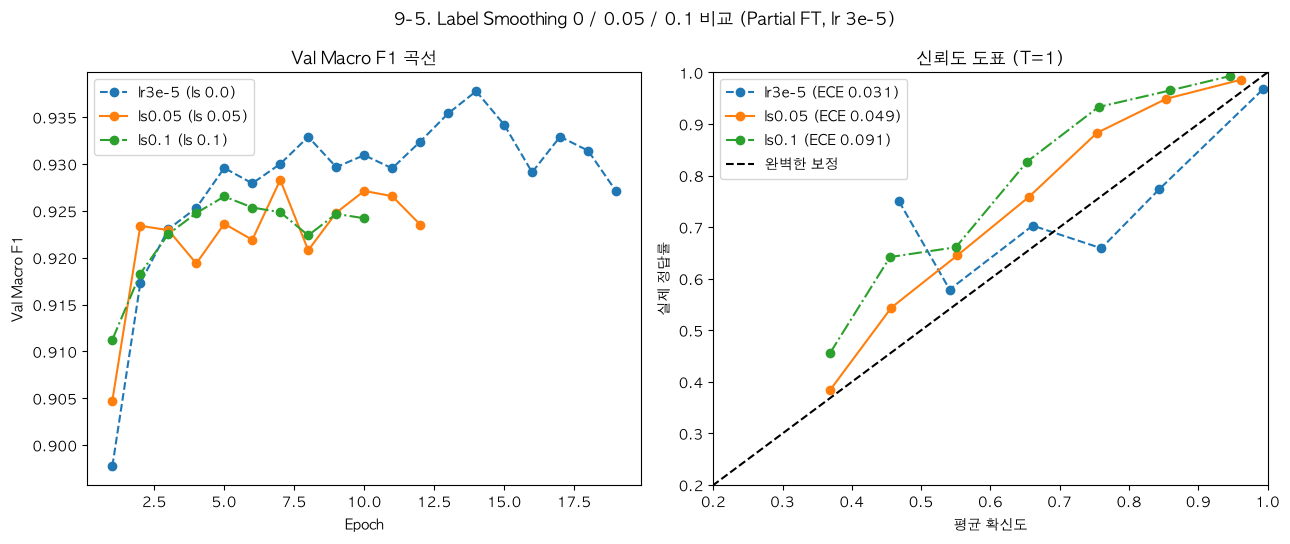

,tag,label_smoothing,Val Macro F1,best epoch,최적 T,ECE (T=1),NLL (최적 T),ECE (최적 T)
0,lr3e-5,0.00,0.9378,14,1.65,0.0310,0.2229,0.0161
1,ls0.05,0.05,0.9283,7,0.75,0.0489,0.2301,0.0056
2,ls0.1,0.10,0.9265,5,0.65,0.0907,0.2362,0.0104


In [35]:
# ===== 9-5-6. label_smoothing 0 / 0.05 / 0.1 비교 (T=1 + 각자 최적 T) =====
LS_TAGS = [("lr3e-5", 0.0), ("ls0.05", 0.05), ("ls0.1", 0.1)]
rows, tabs = [], {}
for tag, ls in LS_TAGS:
    lg = get_val_logits(MODEL_DIR / f"{tag}_partial_ft.pt")
    pred = lg.argmax(1)
    nll_t = [F.cross_entropy(lg / t, val_labels).item() for t in Ts]
    bT = float(Ts[int(np.argmin(nll_t))])
    tab_1, ece_1 = calibration_table(lg, val_labels, T=1.0)
    _, ece_b = calibration_table(lg, val_labels, T=bT)
    h = pd.read_csv(RESULT_DIR / f"history_{tag}_partial_ft.csv")
    tabs[tag] = (tab_1, ece_1, h)
    rows.append({"tag": tag, "label_smoothing": ls,
                 "Val Macro F1": round(f1_score(val_labels.numpy(), pred.numpy(), average="macro"), 4),
                 "best epoch": int(h["val_macro_f1"].idxmax() + 1),
                 "최적 T": bT,
                 "ECE (T=1)": round(ece_1, 4),
                 "NLL (최적 T)": round(min(nll_t), 4),
                 "ECE (최적 T)": round(ece_b, 4)})

ls_all = pd.DataFrame(rows)
ls_all.to_csv(RESULT_DIR / "compare_label_smoothing_all.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for (tag, ls), style in zip(LS_TAGS, ["--", "-", "-."]):
    tab_1, ece_1, h = tabs[tag]
    axes[0].plot(h["epoch"], h["val_macro_f1"], style, marker="o", label=f"{tag} (ls {ls})")
    axes[1].plot(tab_1["평균 확신도"], tab_1["정답률"], style, marker="o", label=f"{tag} (ECE {ece_1:.3f})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Val Macro F1"); axes[0].set_title("Val Macro F1 곡선"); axes[0].legend()
axes[1].plot([0, 1], [0, 1], "k--", label="완벽한 보정")
axes[1].set_xlim(0.2, 1.0); axes[1].set_ylim(0.2, 1.0)
axes[1].set_xlabel("평균 확신도"); axes[1].set_ylabel("실제 정답률"); axes[1].set_title("신뢰도 도표 (T=1)"); axes[1].legend()
plt.suptitle("9-5. Label Smoothing 0 / 0.05 / 0.1 비교 (Partial FT, lr 3e-5)")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_label_smoothing_all.png", dpi=150, bbox_inches="tight")
plt.show()

ls_all

## 10~11. 오분류 분석 및 VLM 분석

(다음 단계에서 작성)

## 12. 개선 실험

(다음 단계에서 작성)

## 13. 최종 모델 Test 평가

(다음 단계에서 작성)